# 3. Modelagem
**Validação:** `StratifiedGroupKFold` com 5 folds, agrupado por paciente (duplicados nunca ficam dos dois lados) e repetido 3 vezes; a taebla mostra a média por fold.
Tudo que depende dos dados (imputação, padronização, limiares da regra, densidades, modelos) é ajustado **dentro** de cada fold, só com o treino.
O conjunto de teste **não** é usado em nenhuma etapa de treino ou validação só na pervisão final.

In [1]:
import warnings
import numpy as np
import pandas as pd
from scipy.stats import norm
from scipy.special import ndtri
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.model_selection import StratifiedGroupKFold, GroupKFold, cross_validate
from sklearn.metrics import make_scorer, recall_score
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import VotingClassifier
from xgboost import XGBClassifier
warnings.filterwarnings('ignore')   # esconde avisos que não mudam os resultados

treino = pd.read_csv('dados/treino_limpo.csv')
teste = pd.read_csv('dados/teste_limpo.csv')

# Variáveis usadas pelos modelos
FEATURES = ['age', 'bmi', 'sbp', 'dbp', 'fam_hist', 'activity', 'glucose', 'hba1c', 'trig', 'site']
X = treino[FEATURES]
y = treino['class']
grupos = treino['patient']   # o mesmo paciente nunca fica no treino e na validação ao mesmo tempo

# Métricas da competição
METRICAS = {
    'precisao': 'precision',
    'recall_diabetes': 'recall',
    'recall_controle': make_scorer(recall_score, pos_label=0),
    'f1_macro': 'f1_macro',
}


def avaliar(modelo, repeticoes=3):
    """Validação cruzada com 5 partes agrupadas por paciente, repetida algumas vezes.
    Devolve a média de cada métrica."""
    notas = {'precisao': [], 'recall_diabetes': [], 'recall_controle': [], 'f1_macro': []}
    for semente in range(repeticoes):
        divisao = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=semente)
        resultado = cross_validate(modelo, X, y, groups=grupos, scoring=METRICAS, cv=divisao, error_score='raise')
        for metrica in METRICAS:
            notas[metrica].extend(resultado['test_' + metrica])

    medias = {}
    for metrica in notas:
        medias[metrica] = np.mean(notas[metrica])
    return medias

## 3.1 KNN, Árvore de Decisão e Rede Neural
Valores ausentes → mediana + indicador de ausência; padronização (z-score).

In [2]:
def com_preparacao(modelo):
    """Antes do modelo: preenche ausentes com a mediana (marcando onde faltava) e padroniza as variáveis."""
    return make_pipeline(SimpleImputer(strategy='median', add_indicator=True), StandardScaler(), modelo)


modelos = {
    'KNN': com_preparacao(KNeighborsClassifier(n_neighbors=11, weights='distance')),
    'Árvore de decisão': com_preparacao(DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, random_state=0)),
    'Rede neural (MLP)': com_preparacao(MLPClassifier(hidden_layer_sizes=(16,), alpha=1.0, max_iter=3000, random_state=0)),
}

resultados = {}
for nome, modelo in modelos.items():
    resultados[nome] = avaliar(modelo)
pd.DataFrame(resultados).T.round(3)

,precisao,recall_diabetes,recall_controle,f1_macro
KNN,0.855,0.739,0.864,0.798
Árvore de decisão,0.877,0.870,0.865,0.865
Rede neural (MLP),0.912,0.877,0.909,0.892


## 3.2 Melhoria 1 — regra clínica em duas etapas
1. HbA1c ≥ 6,5% (critério da ADA) ou glicose acima do maior valor visto entre os controles **do treino** → **diabetes**. Os limiares são aprendidos dentro de cada fold, só com os dados de treino (sem vazamento para a validação).
2. Senão, o modelo decide, treeinado **só com os casos ambíguos**.

In [3]:
class Regra:
    """Regra clínica: HbA1c >= 6,5% (critério da ADA) ou glicose acima do maior valor visto entre os controles do treino."""

    def fit(self, X, y):
        controles = np.asarray(y) == 0
        maior_hba1c_controle = np.nanmax(X['hba1c'].values[controles])
        # 6,5% é o critério clínico; o limite só subiria se algum controle do treino passasse disso
        self.limite_hba1c = max(6.5, maior_hba1c_controle + 1e-6)
        self.limite_glicose = np.nanmax(X['glucose'].values[controles])
        return self

    def aplica(self, X):
        """Devolve True para os pacientes que a regra classifica como diabéticos."""
        hba1c_alta = X['hba1c'] >= self.limite_hba1c
        glicose_alta = X['glucose'] > self.limite_glicose
        return (hba1c_alta | glicose_alta).values


class Base(ClassifierMixin, BaseEstimator):
    """Base dos nossos modelos: a classe prevista é 1 quando a probabilidade passa de 0,5."""
    classes_ = np.array([0, 1])

    def predict(self, X):
        probabilidade = self.predict_proba(X)[:, 1]
        return (probabilidade > 0.5).astype(int)


class DuasEtapas(Base):
    """Etapa 1: a regra clínica. Etapa 2: o modelo decide os casos ambíguos (e só aprende com eles)."""

    def __init__(self, modelo):
        self.modelo = modelo

    def fit(self, X, y):
        self.regra_ = Regra().fit(X, y)
        ambiguos = ~self.regra_.aplica(X)
        self.modelo_ = clone(self.modelo)
        self.modelo_.fit(X[ambiguos], y[ambiguos])
        return self

    def predict_proba(self, X):
        probabilidade = self.modelo_.predict_proba(X)[:, 1]
        probabilidade[self.regra_.aplica(X)] = 1.0   # quem cai na regra é diabético
        return np.column_stack([1 - probabilidade, probabilidade])


for nome, modelo in modelos.items():
    resultados[nome + ' + regra'] = avaliar(DuasEtapas(modelo))
pd.DataFrame(resultados).T.round(3)

,precisao,recall_diabetes,recall_controle,f1_macro
KNN,0.855,0.739,0.864,0.798
Árvore de decisão,0.877,0.870,0.865,0.865
Rede neural (MLP),0.912,0.877,0.909,0.892
KNN + regra,0.975,0.799,0.977,0.883
Árvore de decisão + regra,0.910,0.842,0.908,0.872
Rede neural (MLP) + regra,0.932,0.875,0.931,0.901


## 3.3 Melhoria 2 — separar a evidência glicêmica da não glicêmica
O notebook 2 mostrou que, **dentro de cada classe**, glicose e HbA1c quase não se correlacionam com o resto. Pelo teorema de Bayes:

**P(diabetes | x) ∝ P(diabetes | variáveis não glicêmicas) × razão de verossimilhança(glicose, HbA1c)**

A primeira parte pode ser aprendida com **todos** os pacientes (281 diabéticos), e não só com os 67 diabéticos ambíguos que a etapa 2 acima enxerga.
- **Bayes semi-ingênuo:** estima a distribuição de cada variável em cada classe (KDE para as contínuas, frequências para as categóricas) e usa uma **cópula gaussiana** para os dois blocos correlacionados (idade–pressão e glicose–HbA1c). Valores ausentes são simplesmente ignorados.
- **Híbridos:** KNN, árvore e MLP aprendem a parte não glicêmica com todos os pacientes; glicose e HbA1c entram pela razão de verossimilhança do Bayes.

In [4]:
NAO_GLICEMICAS = ['age', 'bmi', 'sbp', 'dbp', 'fam_hist', 'activity', 'trig', 'site']
GLICEMICAS = ['glucose', 'hba1c']
CONTINUAS = ['age', 'sbp', 'dbp', 'bmi', 'trig', 'glucose', 'hba1c']
BLOCOS = [['age', 'sbp', 'dbp'], ['glucose', 'hba1c']]   # variáveis correlacionadas dentro de cada classe
CATEGORICAS = {'activity': 4, 'fam_hist': 2, 'site': 7}  # variável: número de categorias


def logit(probabilidade):
    """Transforma uma probabilidade em log da razão de chances: log(p / (1 - p))."""
    p = np.clip(probabilidade, 1e-6, 1 - 1e-6)   # evita dividir por zero
    return np.log(p / (1 - p))


def sigmoide(log_chance):
    """Faz o caminho inverso: do log da razão de chances de volta para probabilidade."""
    return 1 / (1 + np.exp(-log_chance))


def faixa_do_site(site):
    """Agrupa o número do local de coleta em 7 faixas: 1, 2, 3, 4-5, 6-10, 11-20 e mais de 20."""
    return np.digitize(site, [1, 2, 3, 5, 10, 20], right=True)


class KDE:
    """Estimativa de densidade por núcleo: uma pequena curva normal sobre cada valor do treino, somadas."""

    def __init__(self, valores, ajuste_banda):
        self.valores = np.asarray(valores, dtype=float)
        desvio = self.valores.std(ddof=1)
        q75, q25 = np.percentile(self.valores, [75, 25])
        iqr = (q75 - q25) / 1.349
        if iqr > 0:
            espalhamento = min(desvio, iqr)
        else:
            espalhamento = desvio
        # largura de cada curva (regra de Silverman, multiplicada por um ajuste)
        self.banda = ajuste_banda * 1.06 * espalhamento * len(self.valores) ** -0.2
        # densidade mínima, para nenhum valor ter probabilidade zero
        self.piso = 1e-3 / (np.ptp(self.valores) + 6 * desvio)

    def _distancias(self, x):
        """Distância (medida em larguras de banda) de cada x até cada valor do treino."""
        return (np.asarray(x)[:, None] - self.valores) / self.banda

    def log_densidade(self, x):
        densidade = norm.pdf(self._distancias(x)).mean(axis=1) / self.banda
        return np.log((1 - 1e-3) * densidade + self.piso)

    def escore_normal(self, x):
        """Posição de x na distribuição, convertida para a escala normal padrão (usado na cópula)."""
        acumulada = norm.cdf(self._distancias(x)).mean(axis=1)
        return ndtri(np.clip(acumulada, 1e-6, 1 - 1e-6))


class BayesSemiIngenuo(Base):
    """Calcula P(x | diabetes) e P(x | controle) variável por variável e junta tudo pelo teorema de Bayes.
    Valores ausentes são simplesmente ignorados."""

    def __init__(self, ajuste_banda=1.6):
        self.ajuste_banda = ajuste_banda

    def fit(self, X, y):
        self.regra_ = Regra().fit(X, y)
        y = np.asarray(y)
        X = X.assign(site=faixa_do_site(X['site']))
        self.log_chance_inicial_ = np.log(y.mean() / (1 - y.mean()))   # proporção de diabéticos no treino

        self.kde_ = {}          # densidades das variáveis contínuas, por classe
        self.frequencias_ = {}  # log das frequências das variáveis categóricas, por classe
        self.correlacoes_ = {}  # matrizes de correlação da cópula, por classe e bloco
        for classe in (0, 1):
            dados_da_classe = X[y == classe]

            self.kde_[classe] = {}
            for coluna in CONTINUAS:
                self.kde_[classe][coluna] = KDE(dados_da_classe[coluna].dropna(), self.ajuste_banda)

            self.frequencias_[classe] = {}
            for coluna, n_categorias in CATEGORICAS.items():
                valores = dados_da_classe[coluna].dropna().astype(int)
                contagem = np.bincount(valores, minlength=n_categorias) + 1   # +1: suavização de Laplace
                self.frequencias_[classe][coluna] = np.log(contagem / (len(valores) + n_categorias))

            for numero_bloco, bloco in enumerate(BLOCOS):
                self.correlacoes_[classe, numero_bloco] = self._correlacao(classe, dados_da_classe, bloco)
        return self

    def _escores(self, classe, X, bloco):
        """Escores normais das variáveis de um bloco (NaN onde o valor está ausente)."""
        Z = np.full((len(X), len(bloco)), np.nan)
        for j, coluna in enumerate(bloco):
            presente = X[coluna].notna().values
            valores = X[coluna].values[presente].astype(float)
            Z[presente, j] = self.kde_[classe][coluna].escore_normal(valores)
        return Z

    def _correlacao(self, classe, X, bloco):
        """Correlação entre os escores normais do bloco, ajustada para ser uma matriz válida."""
        R = pd.DataFrame(self._escores(classe, X, bloco)).corr().values
        autovalores, autovetores = np.linalg.eigh(R)
        autovalores = np.clip(autovalores, 1e-3, None)        # nenhum autovalor zero ou negativo
        R = (autovetores * autovalores) @ autovetores.T
        desvios = np.sqrt(np.diag(R))
        return R / np.outer(desvios, desvios)                 # volta a ter 1 na diagonal

    def _log_copula(self, classe, X, numero_bloco):
        """Log-densidade da cópula gaussiana de um bloco, usando só as colunas presentes em cada linha."""
        Z = self._escores(classe, X, BLOCOS[numero_bloco])
        presentes = ~np.isnan(Z)
        resultado = np.zeros(len(X))
        for padrao in np.unique(presentes, axis=0):           # cada combinação de colunas presentes
            if padrao.sum() < 2:
                continue                                       # com menos de 2 colunas não há correlação para usar
            linhas = (presentes == padrao).all(axis=1)
            colunas = np.flatnonzero(padrao)
            R = self.correlacoes_[classe, numero_bloco][np.ix_(colunas, colunas)]
            z = Z[np.ix_(linhas, colunas)]
            matriz = np.linalg.inv(R) - np.eye(len(colunas))
            forma_quadratica = np.sum((z @ matriz) * z, axis=1)
            resultado[linhas] = -0.5 * forma_quadratica - 0.5 * np.linalg.slogdet(R)[1]
        return resultado

    def termos(self, X):
        """Contribuição de cada variável para o log da razão de chances (diabetes contra controle)."""
        X = X.assign(site=faixa_do_site(X['site']))
        termos = pd.DataFrame(index=X.index)

        for coluna in CONTINUAS:
            valores = X[coluna].values.astype(float)
            presente = ~np.isnan(valores)
            termo = np.zeros(len(valores))
            densidade_diabetes = self.kde_[1][coluna].log_densidade(valores[presente])
            densidade_controle = self.kde_[0][coluna].log_densidade(valores[presente])
            termo[presente] = densidade_diabetes - densidade_controle
            termos[coluna] = termo

        for coluna in CATEGORICAS:
            valores = X[coluna].values
            presente = ~np.isnan(valores)
            categoria = valores[presente].astype(int)
            termo = np.zeros(len(valores))
            termo[presente] = self.frequencias_[1][coluna][categoria] - self.frequencias_[0][coluna][categoria]
            termos[coluna] = termo

        termos['copula_idade_pressao'] = self._log_copula(1, X, 0) - self._log_copula(0, X, 0)
        termos['copula_glicose_hba1c'] = self._log_copula(1, X, 1) - self._log_copula(0, X, 1)
        # evidência glicêmica completa (usada pelos modelos híbridos)
        termos['glicemia'] = termos['glucose'] + termos['hba1c'] + termos['copula_glicose_hba1c']
        return termos

    def predict_proba(self, X):
        termos = self.termos(X).drop(columns='glicemia')
        log_chance = self.log_chance_inicial_ + termos.sum(axis=1).values
        probabilidade = sigmoide(np.clip(log_chance, -30, 30))
        probabilidade[self.regra_.aplica(X)] = 1.0
        return np.column_stack([1 - probabilidade, probabilidade])


class Hibrido(Base):
    """KNN, árvore ou MLP aprendem P(diabetes | variáveis não glicêmicas) com TODOS os pacientes;
    a glicose e a HbA1c entram pela evidência calculada pelo Bayes."""

    def __init__(self, modelo):
        self.modelo = modelo

    def fit(self, X, y):
        self.modelo_ = clone(self.modelo)
        self.modelo_.fit(X[NAO_GLICEMICAS], y)
        self.bayes_ = BayesSemiIngenuo().fit(X, y)
        return self

    def predict_proba(self, X):
        probabilidade_nao_glicemica = self.modelo_.predict_proba(X[NAO_GLICEMICAS])[:, 1]
        probabilidade_nao_glicemica = np.clip(probabilidade_nao_glicemica, 0.01, 0.99)
        log_chance = logit(probabilidade_nao_glicemica) + self.bayes_.termos(X)['glicemia'].values
        probabilidade = sigmoide(log_chance)
        probabilidade[self.bayes_.regra_.aplica(X)] = 1.0
        return np.column_stack([1 - probabilidade, probabilidade])


hibridos = {
    'KNN híbrido': Hibrido(com_preparacao(KNeighborsClassifier(n_neighbors=35, weights='distance'))),
    'Árvore híbrida': Hibrido(com_preparacao(DecisionTreeClassifier(max_depth=3, min_samples_leaf=20, random_state=0))),
    'Rede neural (MLP) híbrida': Hibrido(com_preparacao(MLPClassifier((8,), activation='tanh', alpha=1.0, max_iter=3000, random_state=0))),
    'Bayes semi-ingênuo': BayesSemiIngenuo(),
}
for nome, modelo in hibridos.items():
    resultados[nome] = avaliar(modelo)
pd.DataFrame(resultados).T.round(3)

,precisao,recall_diabetes,recall_controle,f1_macro
KNN,0.855,0.739,0.864,0.798
Árvore de decisão,0.877,0.870,0.865,0.865
Rede neural (MLP),0.912,0.877,0.909,0.892
KNN + regra,0.975,0.799,0.977,0.883
Árvore de decisão + regra,0.910,0.842,0.908,0.872
Rede neural (MLP) + regra,0.932,0.875,0.931,0.901
KNN híbrido,0.974,0.852,0.976,0.910
Árvore híbrida,0.945,0.873,0.947,0.907
Rede neural (MLP) híbrida,0.970,0.898,0.971,0.932
Bayes semi-ingênuo,0.973,0.898,0.973,0.933


## 3.4 Melhoria 3 — boosting fatorado e ensemble final
- **Boosting fatorado:** etapa 1 = XGBoost monotônico com as variáveis não glicêmicas em **todos** os pacientes; etapa 2 = XGBoost só com glicose/HbA1c nos casos ambíguos, **partindo da evidência da etapa 1** (`base_margin`).
- **Ensemble final:** média das probabilidades do Bayes semi-ingênuo e do boosting fatorado — duas famílias diferentes de modelo, que erram em pacientes diferentes.

In [5]:
# Sentido permitido para cada variável: 1 = o risco só pode subir com ela; -1 = só pode cair
SENTIDO = {'hba1c': 1, 'glucose': 1, 'age': 1, 'bmi': 1, 'sbp': 1, 'dbp': 1, 'trig': 1, 'fam_hist': 1, 'activity': -1}


def criar_xgboost(colunas, n_arvores):
    """XGBoost com árvores de um nível e restrições de sentido (monotônicas) nas colunas usadas."""
    restricoes = {}
    for coluna, sentido in SENTIDO.items():
        if coluna in colunas:
            restricoes[coluna] = sentido
    if len(colunas) > 2:
        fracao_colunas = 0.8
    else:
        fracao_colunas = 1.0
    return XGBClassifier(n_estimators=n_arvores, max_depth=1, learning_rate=0.05, subsample=0.8,
                         colsample_bytree=fracao_colunas, monotone_constraints=restricoes, random_state=0, n_jobs=1)


class BoostingFatorado(Base):
    """Etapa 1: XGBoost com as variáveis não glicêmicas em TODOS os pacientes.
    Etapa 2: XGBoost com glicose e HbA1c só nos casos ambíguos, partindo da evidência da etapa 1."""

    def fit(self, X, y):
        X = X.reset_index(drop=True)
        y = np.asarray(y)
        self.regra_ = Regra().fit(X, y)
        ambiguos = ~self.regra_.aplica(X)

        # Evidência da etapa 1 "fora da amostra": cada paciente recebe a previsão de um modelo que não o viu.
        # Linhas idênticas (pacientes duplicados) ficam sempre na mesma parte.
        evidencia = np.zeros(len(y))
        duplicados = pd.util.hash_pandas_object(X, index=False).values
        divisao = GroupKFold(n_splits=5, shuffle=True, random_state=0)
        for linhas_treino, linhas_validacao in divisao.split(X, y, duplicados):
            modelo = criar_xgboost(NAO_GLICEMICAS, 1000)
            modelo.fit(X.loc[linhas_treino, NAO_GLICEMICAS], y[linhas_treino])
            probabilidade = modelo.predict_proba(X.loc[linhas_validacao, NAO_GLICEMICAS])[:, 1]
            evidencia[linhas_validacao] = logit(probabilidade)

        self.etapa1_ = criar_xgboost(NAO_GLICEMICAS, 1000)
        self.etapa1_.fit(X[NAO_GLICEMICAS], y)
        self.etapa2_ = criar_xgboost(GLICEMICAS, 150)
        self.etapa2_.fit(X.loc[ambiguos, GLICEMICAS], y[ambiguos], base_margin=evidencia[ambiguos])
        return self

    def predict_proba(self, X):
        evidencia = logit(self.etapa1_.predict_proba(X[NAO_GLICEMICAS])[:, 1])
        probabilidade = self.etapa2_.predict_proba(X[GLICEMICAS], base_margin=evidencia)[:, 1]
        probabilidade[self.regra_.aplica(X)] = 1.0
        return np.column_stack([1 - probabilidade, probabilidade])


def criar_modelo_final():
    """Modelo final: média das probabilidades do Bayes semi-ingênuo e do boosting fatorado."""
    return VotingClassifier([('bayes', BayesSemiIngenuo()), ('boosting', BoostingFatorado())], voting='soft')


resultados['Boosting fatorado'] = avaliar(BoostingFatorado())
resultados['Final: Bayes + Boosting'] = avaliar(criar_modelo_final())
tabela = pd.DataFrame(resultados).T.round(3)
tabela

,precisao,recall_diabetes,recall_controle,f1_macro
KNN,0.855,0.739,0.864,0.798
Árvore de decisão,0.877,0.870,0.865,0.865
Rede neural (MLP),0.912,0.877,0.909,0.892
KNN + regra,0.975,0.799,0.977,0.883
Árvore de decisão + regra,0.910,0.842,0.908,0.872
Rede neural (MLP) + regra,0.932,0.875,0.931,0.901
KNN híbrido,0.974,0.852,0.976,0.910
Árvore híbrida,0.945,0.873,0.947,0.907
Rede neural (MLP) híbrida,0.970,0.898,0.971,0.932
Bayes semi-ingênuo,0.973,0.898,0.973,0.933


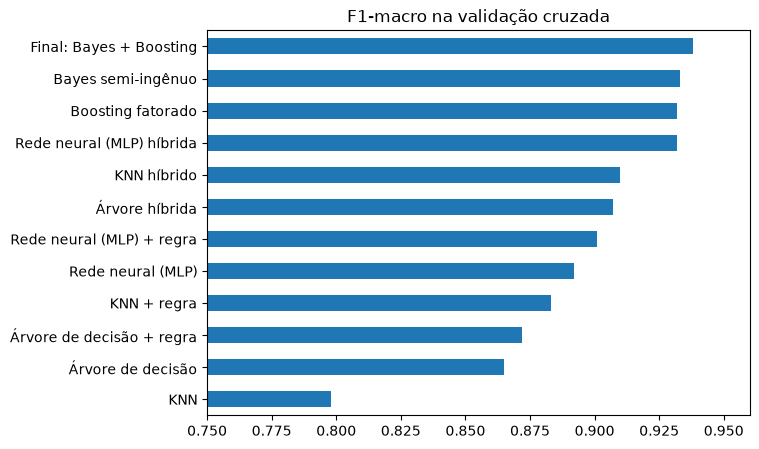

In [6]:
tabela['f1_macro'].sort_values().plot.barh(xlim=(0.75, 0.96), title='F1-macro na validação cruzada', figsize=(7, 5));

## 3.5 Modelo final
Treina o ensemble final com todo o treino e prevê o teste.

class
0    160
1    152
Name: count, dtype: int64


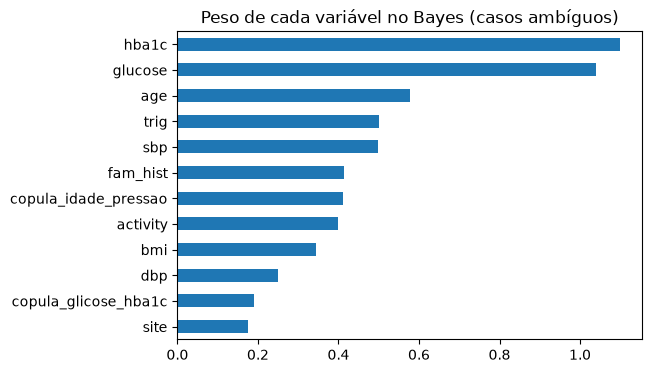

In [7]:
# Treina o modelo final com todo o treino e prevê o teste
modelo_final = criar_modelo_final()
modelo_final.fit(X, y)
previsoes = modelo_final.predict(teste[FEATURES])

# Monta o arquivo de submissão na ordem do modelo do Kaggle
submissao = pd.read_csv('submission_template.csv')
previsao_por_id = dict(zip(teste['id'], previsoes))
submissao['class'] = submissao['id'].map(previsao_por_id)
submissao.to_csv('submission.csv', index=False)
print(submissao['class'].value_counts())

# Quanto cada variável pesa no Bayes, nos casos ambíguos
bayes = modelo_final.estimators_[0]
ambiguos = ~bayes.regra_.aplica(X)
pesos = bayes.termos(X[ambiguos]).drop(columns='glicemia').abs().mean()
pesos.sort_values().plot.barh(title='Peso de cada variável no Bayes (casos ambíguos)', figsize=(6, 4));

## Conclusões
| Modelo | F1-macro |
|---|---|
| KNN / Árvore / MLP | 0,80 / 0,87 / 0,89 |
| … + regra | 0,88 / 0,87 / 0,90 |
| … híbridos | 0,91 / 0,91 / 0,93 |
| Bayes semi-ingênuo / Boosting fatorado | 0,93 / 0,93 |
| **Final: Bayes + Boosting** | **0,94** (validação aninhada: 0,935) |

- O ganho veio da **estrutura dos dados**: regra clínica + evidência não glicêmica aprendida com todos os 281 diabéticos.
- Tudo é ajustado dentro de cada fold; o teste só é usado na previsão final.
- Dados artificiais (SMOTE etc.), redes modernas (TabM, RealMLP), TabPFN/TabICL, CatBoost e outras técnicas foram testados e não melhoraram (ver relatório).